# Notebook 2 · Fine-tuning de Stable Diffusion con `diffusers` y LoRA

**Especialización en Inteligencia Artificial – Universidad de Cundinamarca**<br>
**Asignatura:** Deep Learning – Conceptos (604013) · **Actividad:** R2-A5-S14 Generación

En el notebook anterior construí una GAN desde cero. Aquí paso a la otra gran familia de modelos generativos: los **modelos de difusión**. En concreto trabajo con **Stable Diffusion v1.5**, un *Latent Diffusion Model* (Rombach et al., 2022), que es el modelo que explica el artículo *Latent Diffusion Models: The Architecture behind Stable Diffusion*.

Entrenar un modelo así desde cero está fuera de alcance: se entrenó con cientos de millones de imágenes y miles de horas de GPU. Lo que sí se puede hacer en Colab es **ajustarlo (fine-tuning)** para que aprenda un concepto nuevo. Para eso usé dos técnicas:

- **DreamBooth** (Ruiz et al., 2023): le enseño al modelo un sujeto específico a partir de unas pocas fotos, asociándolo a un identificador raro, `sks`.
- **LoRA** (Hu et al., 2021): en lugar de modificar los ~860 millones de parámetros de la U-Net, congelo el modelo y entreno solo unas matrices pequeñas que se suman a las capas de atención. Así el entrenamiento cabe en una GPU T4 gratuita.

El sujeto que el modelo va a aprender es un perro concreto, a partir de las **5 fotos** del dataset de ejemplo de DreamBooth (`diffusers/dog-example`). La meta es que, después del ajuste, al escribir "*a photo of sks dog*" el modelo genere **ese** perro y no uno cualquiera.

**Requisito:** ejecutar en Google Colab con **GPU T4** (*Entorno de ejecución → Cambiar tipo de entorno de ejecución → GPU T4*).

## 1. Instalación de dependencias y configuración

In [1]:
!pip -q install -U diffusers transformers peft accelerate

In [2]:
import os, time, json, random, math
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn.functional as F
import torchvision.transforms as T
from PIL import Image
import diffusers, peft, transformers
from diffusers import StableDiffusionPipeline, DDPMScheduler, DPMSolverMultistepScheduler
from huggingface_hub import snapshot_download

SEMILLA = 42
random.seed(SEMILLA); np.random.seed(SEMILLA); torch.manual_seed(SEMILLA)
os.makedirs("figuras", exist_ok=True)
plt.rcParams.update({"figure.dpi": 110})

print("diffusers", diffusers.__version__, "| peft", peft.__version__, "| transformers", transformers.__version__, "| torch", torch.__version__)

Disabling torchao because diffusers requires `torchao>=0.15.0` but found version 0.10.0. Upgrade it with `pip install -U 'torchao>=0.15.0'`.


diffusers 0.43.0 | peft 0.22.0 | transformers 5.24.0 | torch 2.14.1+cu130


In [3]:
assert torch.cuda.is_available(), "Este notebook necesita GPU: Entorno de ejecución → Cambiar tipo de entorno de ejecución → GPU T4"
device = "cuda"
DTYPE = torch.float16      # pesos congelados en media precisión para ahorrar memoria
USAR_AMP = True            # precisión mixta durante el entrenamiento
print("GPU:", torch.cuda.get_device_name(0), f"| memoria total: {torch.cuda.get_device_properties(0).total_memory / 1e9:.1f} GB")

GPU: Tesla T4 | memoria total: 15.6 GB


## 2. Carga del modelo base

Stable Diffusion no es una sola red, sino cuatro piezas que trabajan juntas:

| Componente | Función |
|---|---|
| **Tokenizer + Text Encoder (CLIP)** | Convierte el texto del *prompt* en *embeddings* que guían la generación. |
| **VAE (autoencoder variacional)** | Comprime la imagen de 512×512×3 a un **espacio latente** de 64×64×4 y la reconstruye al final. |
| **U-Net** | Es el corazón del modelo. Predice el ruido presente en un latente, condicionada por el texto a través de capas de *cross-attention*. |
| **Scheduler** | Define cuánto ruido se agrega o se quita en cada paso de tiempo. |

Cargo el *pipeline* completo en media precisión (float16) y luego tomo cada componente por separado.

In [4]:
MODELOS_CANDIDATOS = ["stable-diffusion-v1-5/stable-diffusion-v1-5", "sd-legacy/stable-diffusion-v1-5"]
for MODEL_ID in MODELOS_CANDIDATOS:
    try:
        pipe = StableDiffusionPipeline.from_pretrained(MODEL_ID, torch_dtype=DTYPE)
        break
    except Exception as e:
        print(f"No se pudo cargar {MODEL_ID}: {e}")
pipe = pipe.to(device)
pipe.scheduler = DPMSolverMultistepScheduler.from_config(pipe.scheduler.config)   # 25 pasos de inferencia bastan
pipe.set_progress_bar_config(disable=True)

tokenizer, text_encoder, vae, unet = pipe.tokenizer, pipe.text_encoder, pipe.vae, pipe.unet
noise_scheduler = DDPMScheduler.from_pretrained(MODEL_ID, subfolder="scheduler")   # scheduler de entrenamiento

n = lambda m: sum(p.numel() for p in m.parameters())
print("Modelo:", MODEL_ID)
print(f"U-Net: {n(unet)/1e6:.0f} M parámetros | VAE: {n(vae)/1e6:.0f} M | Text encoder: {n(text_encoder)/1e6:.0f} M")
print("Pasos de difusión en entrenamiento:", noise_scheduler.config.num_train_timesteps,
      "| tipo de predicción:", noise_scheduler.config.prediction_type)

/usr/local/lib/python3.13/dist-packages/diffusers/utils/deprecation_utils.py:23: FutureWarning: `torch_dtype` is deprecated and will be removed in version 1.0.0. Please use `dtype` instead.
  deprecate("torch_dtype", "1.0.0", _TORCH_DTYPE_DEPRECATION_MESSAGE)


model_index.json:   0%|          | 0.00/541 [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 15 files:   0%|          | 0/15 [00:00<?, ?it/s]

Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/396 [00:00<?, ?it/s]

Modelo: stable-diffusion-v1-5/stable-diffusion-v1-5
U-Net: 860 M parámetros | VAE: 84 M | Text encoder: 123 M
Pasos de difusión en entrenamiento: 1000 | tipo de predicción: epsilon


/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_validators.py:206: UserWarning: The `local_dir_use_symlinks` argument is deprecated and ignored in `hf_hub_download`. Downloading to a local directory does not use symlinks anymore.
  warnings.warn(


## 3. Preparación del mini-dataset

El dataset tiene solo 5 fotos del mismo perro. Eso es precisamente lo interesante de DreamBooth: unas pocas imágenes bastan para enseñar un sujeto nuevo, porque el modelo ya "sabe" qué es un perro y solo tiene que aprender **cuál** perro. Las recorto al centro y las llevo a 512×512, que es la resolución nativa de SD 1.5. Todas comparten la misma descripción: `a photo of sks dog`.

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 6 files:   0%|          | 0/6 [00:00<?, ?it/s]

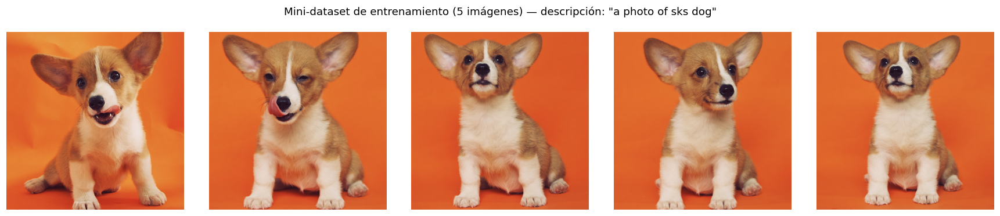

In [5]:
carpeta = snapshot_download("diffusers/dog-example", repo_type="dataset", local_dir="./perro")
rutas = sorted([os.path.join(carpeta, f) for f in os.listdir(carpeta) if f.lower().endswith((".jpg", ".jpeg", ".png"))])
PROMPT_INSTANCIA = "a photo of sks dog"

preprocesar = T.Compose([T.Resize(512, antialias=True), T.CenterCrop(512)])
fotos = [preprocesar(Image.open(r).convert("RGB")) for r in rutas]

fig, axes = plt.subplots(1, len(fotos), figsize=(3.2 * len(fotos), 3.4))
for ax, im in zip(axes, fotos):
    ax.imshow(im); ax.axis("off")
plt.suptitle(f"Mini-dataset de entrenamiento ({len(fotos)} imágenes) — descripción: \"{PROMPT_INSTANCIA}\"")
plt.tight_layout(); plt.savefig("figuras/sd_dataset.png", bbox_inches="tight"); plt.show()

## 4. El espacio latente: ¿por qué Stable Diffusion es "latente"?

Los primeros modelos de difusión trabajaban directamente sobre los píxeles, lo que era carísimo. La idea clave de los *Latent Diffusion Models* es aplicar la difusión **en un espacio comprimido**. El VAE convierte cada imagen de 512×512×3 (786.432 valores) en un latente de 64×64×4 (16.384 valores), es decir, **48 veces menos datos**, y aun así puede reconstruirla con muy poca pérdida.

Aquí codifico una de las fotos, muestro sus 4 canales latentes y la vuelvo a decodificar.

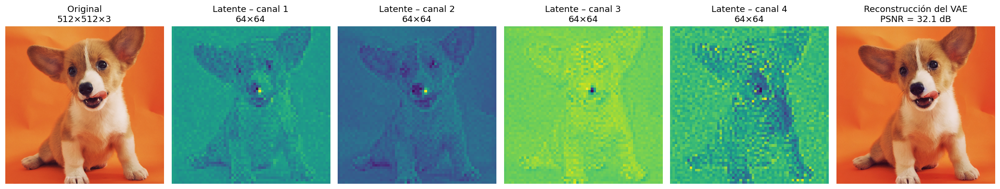

Forma del latente: (1, 4, 64, 64) | compresión: 48x | PSNR de reconstrucción: 32.1 dB


In [6]:
a_tensor = T.Compose([T.ToTensor(), T.Normalize([0.5], [0.5])])
SF = vae.config.scaling_factor

@torch.no_grad()
def codificar(imgs_pil):
    x = torch.stack([a_tensor(im) for im in imgs_pil]).to(device, DTYPE)
    return vae.encode(x).latent_dist

@torch.no_grad()
def decodificar(latentes):
    x = vae.decode(latentes.to(DTYPE) / SF).sample
    return ((x.float().clamp(-1, 1) + 1) / 2).permute(0, 2, 3, 1).cpu().numpy()

lat = codificar([fotos[0]]).mean * SF
recon = decodificar(lat)[0]
original = np.asarray(fotos[0]) / 255.0
psnr = 10 * np.log10(1 / np.mean((original - recon) ** 2))

fig, axes = plt.subplots(1, 6, figsize=(19, 3.6))
axes[0].imshow(fotos[0]); axes[0].set_title("Original\n512×512×3")
for c in range(4):
    axes[c + 1].imshow(lat[0, c].float().cpu(), cmap="viridis"); axes[c + 1].set_title(f"Latente – canal {c + 1}\n64×64")
axes[5].imshow(recon); axes[5].set_title(f"Reconstrucción del VAE\nPSNR = {psnr:.1f} dB")
for ax in axes: ax.axis("off")
plt.tight_layout(); plt.savefig("figuras/sd_espacio_latente.png", bbox_inches="tight"); plt.show()

print(f"Forma del latente: {tuple(lat.shape)} | compresión: {512*512*3 / lat[0].numel():.0f}x | PSNR de reconstrucción: {psnr:.1f} dB")

## 5. El proceso de difusión, en las dos direcciones

### 5.1 Proceso directo: añadir ruido
Durante el entrenamiento, al latente limpio $x_0$ se le suma ruido gaussiano según un paso de tiempo $t$ entre 0 y 999:

$$x_t = \sqrt{\bar\alpha_t}\, x_0 + \sqrt{1 - \bar\alpha_t}\, \epsilon, \qquad \epsilon \sim \mathcal{N}(0, I)$$

Cuanto mayor es $t$, más se parece $x_t$ a ruido puro. Abajo se ve qué pasa con la imagen al decodificar latentes cada vez más ruidosos.

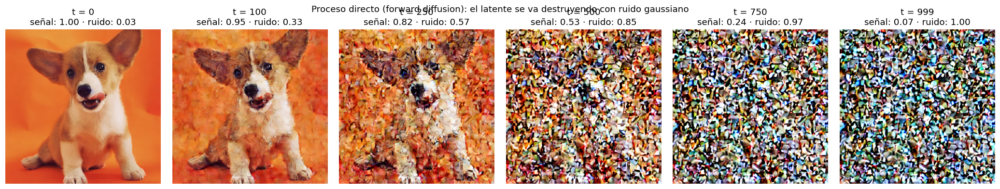

In [7]:
pasos_t = [0, 100, 250, 500, 750, 999]
ruido = torch.randn(lat.shape, generator=torch.Generator(device).manual_seed(0), device=device, dtype=lat.dtype)
ruidosos = torch.cat([noise_scheduler.add_noise(lat, ruido, torch.tensor([t], device=device)) for t in pasos_t])
imgs = decodificar(ruidosos)

fig, axes = plt.subplots(1, len(pasos_t), figsize=(19, 3.6))
for ax, im, t in zip(axes, imgs, pasos_t):
    a_bar = noise_scheduler.alphas_cumprod[t].item()
    ax.imshow(im); ax.set_title(f"t = {t}\nseñal: {math.sqrt(a_bar):.2f} · ruido: {math.sqrt(1 - a_bar):.2f}"); ax.axis("off")
plt.suptitle("Proceso directo (forward diffusion): el latente se va destruyendo con ruido gaussiano")
plt.tight_layout(); plt.savefig("figuras/sd_proceso_directo.png", bbox_inches="tight"); plt.show()

### 5.2 Proceso inverso: quitar ruido, guiado por el texto
Para generar se hace lo contrario: se parte de ruido puro y, en cada paso, la U-Net predice cuánto ruido hay para restarlo poco a poco. El texto entra a la U-Net por las capas de *cross-attention*. Además se usa **classifier-free guidance**: el modelo predice el ruido con y sin el prompt, y se amplifica la diferencia entre ambas predicciones según el `guidance_scale`.

Capturé el latente en varios pasos intermedios de una generación para "ver" cómo aparece la imagen desde el ruido.

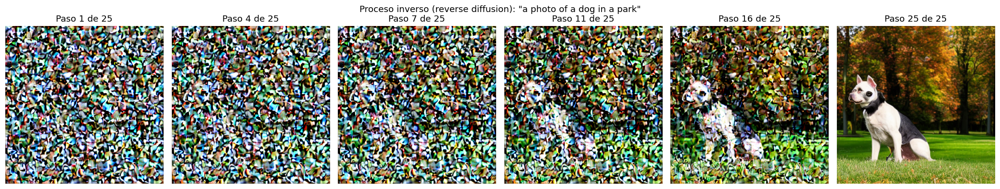

In [8]:
capturas, pasos_captura = {}, [0, 3, 6, 10, 15, 24]

def capturar(pipeline, paso, timestep, kwargs):
    if paso in pasos_captura:
        capturas[paso] = kwargs["latents"].detach().clone()
    return kwargs

_ = pipe("a photo of a dog in a park", num_inference_steps=25, guidance_scale=7.5,
         generator=torch.Generator(device).manual_seed(1),
         callback_on_step_end=capturar, callback_on_step_end_tensor_inputs=["latents"])

fig, axes = plt.subplots(1, len(pasos_captura), figsize=(19, 3.6))
for ax, p in zip(axes, pasos_captura):
    ax.imshow(decodificar(capturas[p])[0]); ax.set_title(f"Paso {p + 1} de 25"); ax.axis("off")
plt.suptitle("Proceso inverso (reverse diffusion): \"a photo of a dog in a park\"")
plt.tight_layout(); plt.savefig("figuras/sd_proceso_inverso.png", bbox_inches="tight"); plt.show()

## 6. Línea base: ¿qué genera el modelo ANTES del fine-tuning?

Antes de entrenar, el modelo no tiene ni idea de qué es `sks dog`: para él, `sks` es una palabra sin significado. Genero cuatro prompts con **semillas fijas**, para comparar después en exactamente las mismas condiciones.

Tiempo medio por imagen (25 pasos, 512×512): 4.0 s


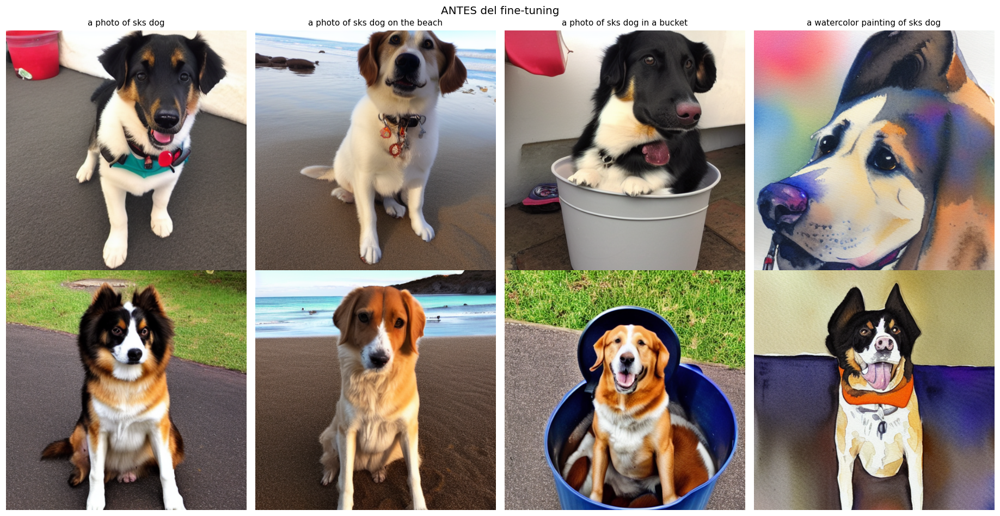

In [9]:
PROMPTS = ["a photo of sks dog",
           "a photo of sks dog on the beach",
           "a photo of sks dog in a bucket",
           "a watercolor painting of sks dog"]
SEMILLAS = [11, 22]

@torch.no_grad()
def generar(prompts, semillas, pasos=25, guia=7.5):
    salida = []
    for p in prompts:
        for s in semillas:
            g = torch.Generator(device).manual_seed(s)
            salida.append(pipe(p, num_inference_steps=pasos, guidance_scale=guia, generator=g).images[0])
    return salida

t0 = time.time()
antes = generar(PROMPTS, SEMILLAS)
t_gen = (time.time() - t0) / len(antes)
print(f"Tiempo medio por imagen (25 pasos, 512×512): {t_gen:.1f} s")

def rejilla(imgs, prompts, semillas, titulo, archivo):
    fig, axes = plt.subplots(len(semillas), len(prompts), figsize=(4.2 * len(prompts), 4.4 * len(semillas)))
    for i, p in enumerate(prompts):
        for j in range(len(semillas)):
            ax = axes[j, i]; ax.imshow(imgs[i * len(semillas) + j]); ax.axis("off")
            if j == 0: ax.set_title(p, fontsize=10)
    plt.suptitle(titulo, fontsize=13); plt.tight_layout(); plt.savefig(archivo, bbox_inches="tight"); plt.show()

rejilla(antes, PROMPTS, SEMILLAS, "ANTES del fine-tuning", "figuras/sd_antes.png")

## 7. Configuración de LoRA

LoRA parte de una observación: al ajustar un modelo grande, el **cambio** en los pesos ($\Delta W$) tiene "rango bajo". Por eso, en lugar de entrenar $\Delta W$ completo (de $d \times d$), se descompone como el producto de dos matrices delgadas:

$$W' = W + \Delta W = W + \frac{\alpha}{r} B A, \qquad B \in \mathbb{R}^{d \times r},\; A \in \mathbb{R}^{r \times d},\; r \ll d$$

$W$ queda congelada y solo se entrenan $A$ y $B$. Apliqué LoRA con rango $r = 8$ a las proyecciones de *query*, *key*, *value* y salida de todas las capas de atención de la U-Net, que es justamente donde el texto se mezcla con la imagen.

In [10]:
from peft import LoraConfig

RANGO = 8
unet.requires_grad_(False); vae.requires_grad_(False); text_encoder.requires_grad_(False)
lora_config = LoraConfig(r=RANGO, lora_alpha=RANGO, init_lora_weights="gaussian",
                         target_modules=["to_k", "to_q", "to_v", "to_out.0"])
unet.add_adapter(lora_config)

# Los pesos de LoRA se entrenan en float32 (más estable); el resto del modelo sigue en float16
parametros_lora = [p for p in unet.parameters() if p.requires_grad]
for p in parametros_lora:
    p.data = p.data.float()

n_lora, n_total = sum(p.numel() for p in parametros_lora), n(unet)
print(f"Parámetros entrenables (LoRA): {n_lora:,}")
print(f"Parámetros totales de la U-Net: {n_total:,}")
print(f"Fracción entrenable: {100 * n_lora / n_total:.2f} %")

/usr/local/lib/python3.13/dist-packages/peft/import_utils.py:195: UserWarning: Found an incompatible version of torchao. Found version 0.10.0, but only versions above 0.16.0 are supported. torchao support in PEFT is disabled; if you want to use a torchao-quantized model with PEFT, please upgrade torchao.
  warnings.warn(


Parámetros entrenables (LoRA): 1,594,368
Parámetros totales de la U-Net: 861,115,332
Fracción entrenable: 0.19 %


## 8. Bucle de fine-tuning en el espacio latente

Cada paso del entrenamiento reproduce exactamente el objetivo con el que se entrenó Stable Diffusion:
1. Tomo una foto (o su versión volteada horizontalmente, como aumento de datos) y la **codifico al espacio latente** con el VAE.
2. Elijo un paso de tiempo $t$ al azar y le **agrego ruido** al latente (proceso directo).
3. La U-Net, condicionada con el texto `a photo of sks dog`, **predice el ruido** agregado.
4. La pérdida es el **error cuadrático medio** entre el ruido real y el predicho, y con ella actualizo solo los pesos LoRA.

Para ahorrar tiempo, codifico las imágenes y el texto una sola vez antes del bucle. Uso además *gradient checkpointing* y precisión mixta para que todo quepa en los 15 GB de la T4.

In [11]:
PASOS = 400
LR = 1e-4
BATCH = 2

# Pre-codificación: 5 fotos + sus versiones espejo = 10 latentes (media y desviación de la distribución del VAE)
todas = fotos + [im.transpose(Image.FLIP_LEFT_RIGHT) for im in fotos]
dist = codificar(todas)
lat_media, lat_std = dist.mean, dist.std

with torch.no_grad():
    ids = tokenizer(PROMPT_INSTANCIA, padding="max_length", max_length=tokenizer.model_max_length,
                    truncation=True, return_tensors="pt").input_ids.to(device)
    emb_texto = text_encoder(ids)[0]

unet.enable_gradient_checkpointing()
unet.train()
optimizador = torch.optim.AdamW(parametros_lora, lr=LR, weight_decay=1e-2)
escalador = torch.amp.GradScaler("cuda", enabled=USAR_AMP)
torch.cuda.reset_peak_memory_stats() if device == "cuda" else None

perdidas, t0 = [], time.time()
for paso in range(1, PASOS + 1):
    idx = torch.randint(0, len(todas), (BATCH,))
    latentes = (lat_media[idx] + lat_std[idx] * torch.randn_like(lat_std[idx])) * SF     # muestreo del VAE
    ruido = torch.randn_like(latentes)
    t = torch.randint(0, noise_scheduler.config.num_train_timesteps, (BATCH,), device=device).long()
    ruidosos = noise_scheduler.add_noise(latentes, ruido, t)                              # proceso directo

    with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=USAR_AMP):
        pred = unet(ruidosos, t, encoder_hidden_states=emb_texto.expand(BATCH, -1, -1)).sample

    objetivo = ruido if noise_scheduler.config.prediction_type == "epsilon" else noise_scheduler.get_velocity(latentes, ruido, t)
    perdida = F.mse_loss(pred.float(), objetivo.float())

    optimizador.zero_grad(set_to_none=True)
    escalador.scale(perdida).backward()
    escalador.unscale_(optimizador)
    torch.nn.utils.clip_grad_norm_(parametros_lora, 1.0)
    escalador.step(optimizador); escalador.update()

    perdidas.append(perdida.item())
    if paso % 50 == 0:
        print(f"Paso {paso:4d}/{PASOS} | pérdida MSE (media últimos 50) = {np.mean(perdidas[-50:]):.4f} | {time.time() - t0:5.0f} s")

t_entreno = time.time() - t0
mem_pico = torch.cuda.max_memory_allocated() / 1e9 if device == "cuda" else 0
print(f"\nEntrenamiento terminado en {t_entreno / 60:.1f} min | memoria GPU pico: {mem_pico:.1f} GB")

unet.eval()
for p in parametros_lora:            # devuelvo LoRA a float16 para la inferencia
    p.data = p.data.to(DTYPE)

Paso   50/400 | pérdida MSE (media últimos 50) = 0.0939 |    30 s
Paso  100/400 | pérdida MSE (media últimos 50) = 0.1025 |    61 s
Paso  150/400 | pérdida MSE (media últimos 50) = 0.1044 |    91 s
Paso  200/400 | pérdida MSE (media últimos 50) = 0.0848 |   122 s
Paso  250/400 | pérdida MSE (media últimos 50) = 0.0878 |   153 s
Paso  300/400 | pérdida MSE (media últimos 50) = 0.0879 |   183 s
Paso  350/400 | pérdida MSE (media últimos 50) = 0.0752 |   214 s
Paso  400/400 | pérdida MSE (media últimos 50) = 0.0760 |   245 s

Entrenamiento terminado en 4.1 min | memoria GPU pico: 3.4 GB


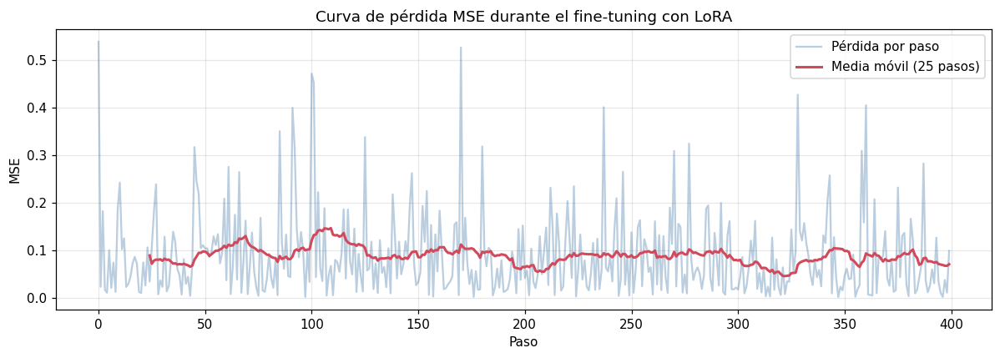

Pérdida media primeros 50 pasos: 0.0939 | últimos 50 pasos: 0.0760


In [12]:
ventana = 25
media_movil = np.convolve(perdidas, np.ones(ventana) / ventana, mode="valid")
plt.figure(figsize=(11, 4))
plt.plot(perdidas, alpha=0.3, color="#1f5f99", label="Pérdida por paso")
plt.plot(range(ventana - 1, len(perdidas)), media_movil, color="#d1495b", lw=2, label=f"Media móvil ({ventana} pasos)")
plt.title("Curva de pérdida MSE durante el fine-tuning con LoRA"); plt.xlabel("Paso"); plt.ylabel("MSE")
plt.legend(); plt.grid(alpha=0.3)
plt.tight_layout(); plt.savefig("figuras/sd_curva_perdida.png", bbox_inches="tight"); plt.show()

print(f"Pérdida media primeros 50 pasos: {np.mean(perdidas[:50]):.4f} | últimos 50 pasos: {np.mean(perdidas[-50:]):.4f}")

Esta curva **no se ve como la de una red de clasificación**, y es normal. En cada paso se escoge un nivel de ruido $t$ al azar: cuando $t$ es grande, predecir el ruido es muy fácil (la pérdida es baja), y cuando $t$ es pequeño es mucho más difícil. Por eso la pérdida salta mucho de un paso a otro, y lo que importa es la tendencia de la media móvil. Además, el modelo base ya predice bien el ruido de fotos de perros en general, así que la pérdida parte baja. El ajuste fino solo afina los detalles de **este** perro en particular.

## 9. Inferencia: comparación ANTES vs. DESPUÉS del fine-tuning

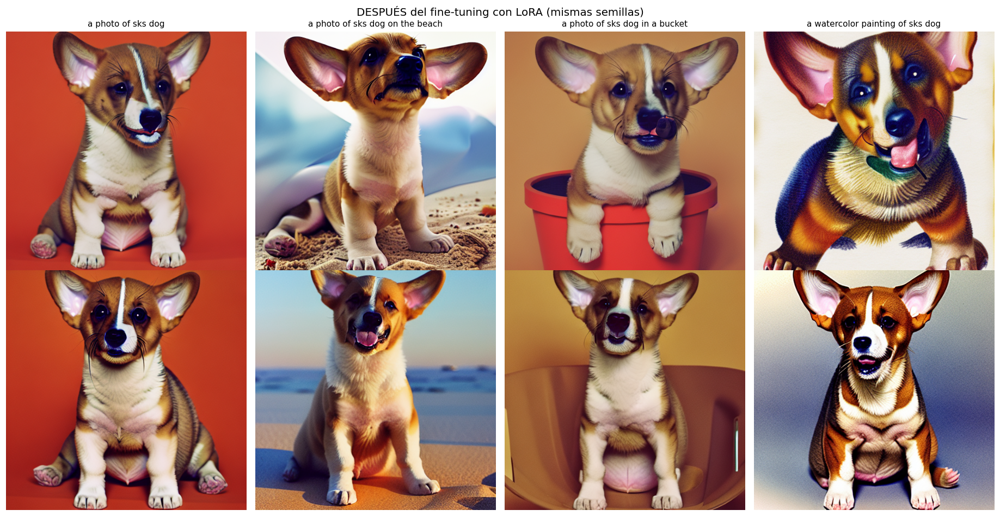

In [13]:
despues = generar(PROMPTS, SEMILLAS)
rejilla(despues, PROMPTS, SEMILLAS, "DESPUÉS del fine-tuning con LoRA (mismas semillas)", "figuras/sd_despues.png")

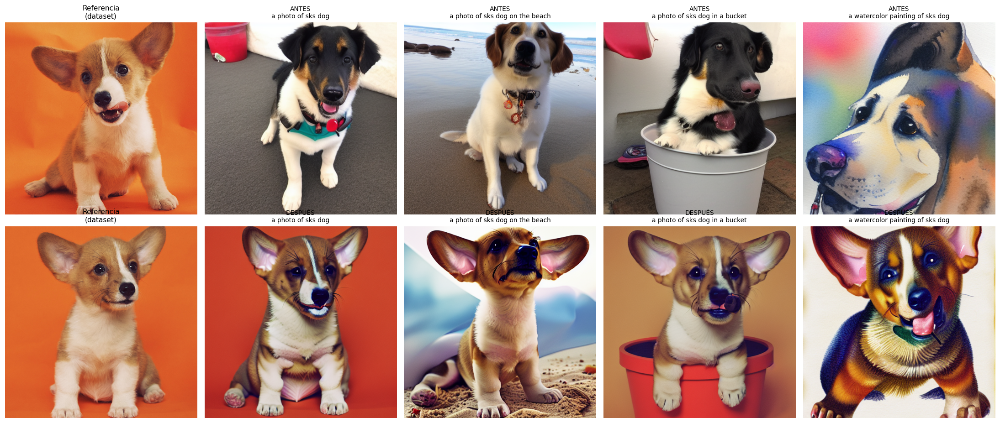

In [14]:
fig, axes = plt.subplots(2, len(PROMPTS) + 1, figsize=(4 * (len(PROMPTS) + 1), 8.4))
axes[0, 0].imshow(fotos[0]); axes[0, 0].set_title("Referencia\n(dataset)", fontsize=10)
axes[1, 0].imshow(fotos[3]); axes[1, 0].set_title("Referencia\n(dataset)", fontsize=10)
for i, p in enumerate(PROMPTS):
    axes[0, i + 1].imshow(antes[i * len(SEMILLAS)]); axes[0, i + 1].set_title(f"ANTES\n{p}", fontsize=9)
    axes[1, i + 1].imshow(despues[i * len(SEMILLAS)]); axes[1, i + 1].set_title(f"DESPUÉS\n{p}", fontsize=9)
for ax in axes.ravel(): ax.axis("off")
plt.tight_layout(); plt.savefig("figuras/sd_comparacion.png", bbox_inches="tight"); plt.show()

## 10. Análisis de resultados

### 10.1 ¿El modelo olvidó lo que es un perro cualquiera? (*language drift*)
Un riesgo de DreamBooth es que el modelo empiece a dibujar **siempre** al perro entrenado, incluso cuando se le pide "un perro" a secas. Esto se conoce como *language drift* o sobreajuste. Para revisarlo genero `a photo of a dog`, sin el identificador, con el adaptador LoRA apagado y prendido.

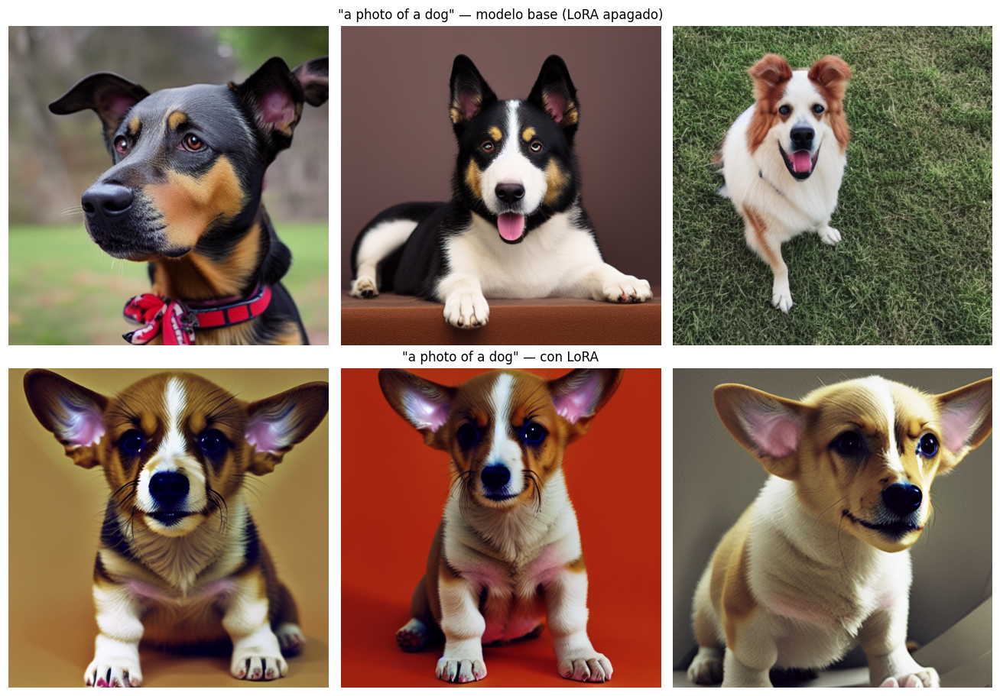

In [15]:
prompt_clase = ["a photo of a dog"]
unet.disable_adapters()
clase_sin = generar(prompt_clase, [5, 6, 7])
unet.enable_adapters()
clase_con = generar(prompt_clase, [5, 6, 7])

fig, axes = plt.subplots(2, 3, figsize=(12, 8.4))
for j in range(3):
    axes[0, j].imshow(clase_sin[j]); axes[1, j].imshow(clase_con[j])
    axes[0, j].axis("off"); axes[1, j].axis("off")
axes[0, 1].set_title("\"a photo of a dog\" — modelo base (LoRA apagado)", fontsize=11)
axes[1, 1].set_title("\"a photo of a dog\" — con LoRA", fontsize=11)
plt.tight_layout(); plt.savefig("figuras/sd_language_drift.png", bbox_inches="tight"); plt.show()

### 10.2 Efecto de la escala de guía (*guidance scale*)
El `guidance_scale` controla qué tanto se "obedece" al texto. Con valores bajos, la imagen es más libre y menos fiel al prompt; con valores altos, se apega más al texto, pero puede saturarse o verse artificial.

Potential NSFW content was detected in one or more images. A black image will be returned instead. Try again with a different prompt and/or seed.


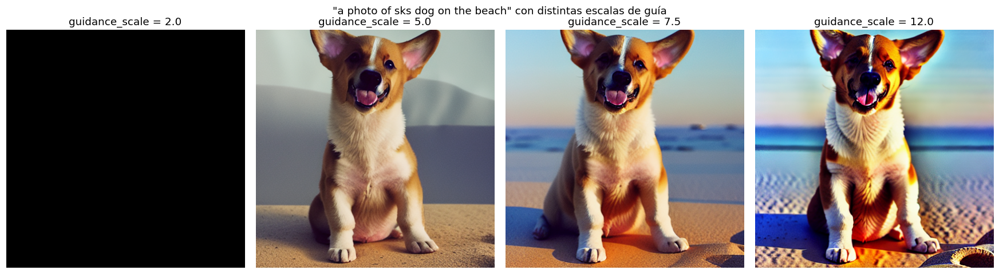

In [16]:
escalas = [2.0, 5.0, 7.5, 12.0]
imgs_guia = [generar(["a photo of sks dog on the beach"], [22], guia=g)[0] for g in escalas]
fig, axes = plt.subplots(1, len(escalas), figsize=(16, 4.4))
for ax, im, g in zip(axes, imgs_guia, escalas):
    ax.imshow(im); ax.set_title(f"guidance_scale = {g}"); ax.axis("off")
plt.suptitle("\"a photo of sks dog on the beach\" con distintas escalas de guía")
plt.tight_layout(); plt.savefig("figuras/sd_guidance.png", bbox_inches="tight"); plt.show()

### 10.3 Tamaño del adaptador entrenado
Una de las mayores ventajas de LoRA es que lo que se guarda es diminuto comparado con el modelo completo. Guardo los pesos y comparo tamaños.

In [17]:
from peft.utils import get_peft_model_state_dict
from diffusers.utils import convert_state_dict_to_diffusers

pesos_lora = convert_state_dict_to_diffusers(get_peft_model_state_dict(unet))
StableDiffusionPipeline.save_lora_weights("lora_sks_dog", unet_lora_layers=pesos_lora, safe_serialization=True)
tam_lora = sum(os.path.getsize(os.path.join("lora_sks_dog", f)) for f in os.listdir("lora_sks_dog")) / 1e6
tam_unet = n_total * 2 / 1e6   # U-Net en float16 (2 bytes por parámetro)
print(f"Tamaño del adaptador LoRA: {tam_lora:.1f} MB | U-Net completa en fp16: {tam_unet:,.0f} MB | relación: {tam_unet / tam_lora:.0f}x más pequeño")

Tamaño del adaptador LoRA: 3.2 MB | U-Net completa en fp16: 1,722 MB | relación: 534x más pequeño


In [18]:
resumen = {
    "modelo": MODEL_ID, "gpu": torch.cuda.get_device_name(0),
    "imagenes_entrenamiento": len(fotos), "prompt_instancia": PROMPT_INSTANCIA,
    "rango_lora": RANGO, "pasos": PASOS, "lr": LR, "batch": BATCH,
    "params_lora": n_lora, "params_unet": n_total, "pct_entrenable": round(100 * n_lora / n_total, 3),
    "tiempo_entrenamiento_min": round(t_entreno / 60, 2), "memoria_pico_gb": round(mem_pico, 2),
    "perdida_inicial_50": round(float(np.mean(perdidas[:50])), 4), "perdida_final_50": round(float(np.mean(perdidas[-50:])), 4),
    "tiempo_por_imagen_s": round(t_gen, 2), "psnr_vae_db": round(float(psnr), 2),
    "tam_lora_mb": round(tam_lora, 2), "tam_unet_fp16_mb": round(tam_unet, 1),
}
with open("resultados_sd.json", "w", encoding="utf-8") as f:
    json.dump(resumen, f, ensure_ascii=False, indent=2)
print(json.dumps(resumen, ensure_ascii=False, indent=2))

{
  "modelo": "stable-diffusion-v1-5/stable-diffusion-v1-5",
  "gpu": "Tesla T4",
  "imagenes_entrenamiento": 5,
  "prompt_instancia": "a photo of sks dog",
  "rango_lora": 8,
  "pasos": 400,
  "lr": 0.0001,
  "batch": 2,
  "params_lora": 1594368,
  "params_unet": 861115332,
  "pct_entrenable": 0.185,
  "tiempo_entrenamiento_min": 4.08,
  "memoria_pico_gb": 3.36,
  "perdida_inicial_50": 0.0939,
  "perdida_final_50": 0.076,
  "tiempo_por_imagen_s": 3.97,
  "psnr_vae_db": 32.12,
  "tam_lora_mb": 3.23,
  "tam_unet_fp16_mb": 1722.2
}


## 11. Conclusiones

- **El espacio latente es lo que hace viable a Stable Diffusion.** El VAE comprimió la foto de 512×512×3 a un latente de 64×64×4, es decir, 48 veces menos datos. Aun así la reconstruyó con un PSNR de 32,1 dB, prácticamente idéntica a simple vista. En los cuatro canales del latente todavía se distingue la silueta del perro.
- **Se vio con claridad el proceso de difusión en las dos direcciones.**
  - En el proceso directo, la imagen se deshace en ruido. Hacia t = 500 ya casi no se reconoce el perro, y en t = 999 queda solo el 7 % de la señal.
  - En el proceso inverso, el perro aparece desde el ruido: primero la silueta, hacia el paso 11; luego la escena completa, en el paso 25.
- **LoRA permitió el ajuste fino con muy pocos recursos.** Solo entrené 1.594.368 parámetros, el 0,19 % de los 861 millones de la U-Net. Fueron 400 pasos en 4,1 minutos, con un pico de 3,4 GB de memoria en la T4. El adaptador final pesa 3,2 MB, frente a 1.722 MB de la U-Net completa en float16: unas 534 veces más pequeño.
- **El modelo aprendió el sujeto.** Antes del ajuste, "sks dog" producía perros cualquiera, de razas y colores distintos. Después, con las mismas semillas, aparece siempre el mismo cachorro tipo corgi:
  - Orejas grandes con el interior rosado.
  - La franja blanca en la frente.
  - El pelaje café y blanco.

  Además respeta el contexto del prompt: lo pone en la playa, dentro de un recipiente y en estilo acuarela. La pérdida MSE es ruidosa por naturaleza, porque el nivel de ruido se escoge al azar en cada paso, pero su media bajó de 0,094 a 0,076.
- **También aparecieron señales claras de sobreajuste.**
  - El fondo naranja de las fotos de entrenamiento se "cuela" en varias imágenes.
  - Algunas texturas se ven caricaturescas o saturadas.
  - Lo más llamativo es el *language drift*: con LoRA activo, "a photo of a dog" (sin `sks`) genera siempre el mismo cachorro, mientras que el modelo base produce razas variadas. El ajuste contaminó la idea general de "perro". La solución que propone DreamBooth es la *prior preservation loss*, que consiste en entrenar también con imágenes de perros genéricos. Otras opciones son reducir los pasos o el rango de LoRA.
- **Sobre la escala de guía.**
  - Con 5 y 7,5 se obtiene el mejor balance.
  - Con 12 los colores se saturan y el contraste se exagera.
  - Con 2 el filtro de seguridad de Stable Diffusion marcó la imagen como contenido inapropiado y la devolvió en negro. Fue un falso positivo, que suele aparecer con guías bajas porque la imagen queda menos definida. Lo dejé tal cual como evidencia de esa limitación.
- **Limitaciones computacionales.** Cada imagen tardó unos 4 segundos en una T4. Entrenar Stable Diffusion desde cero requirió cientos de millones de imágenes y miles de horas de GPU. Por eso, en un entorno como Colab lo realista es adaptar modelos ya entrenados con técnicas como LoRA y no crearlos desde cero.